# Lab 8
## Name: Arnish Manwatkar
## Batch: C-C3
## Roll no: 38
## Lab: ML

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,f1_score,recall_score,precision_score,ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

In [3]:
df =pd.read_csv('ai4i2020.csv')

In [4]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [6]:
df.shape

(10000, 14)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [8]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [11]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

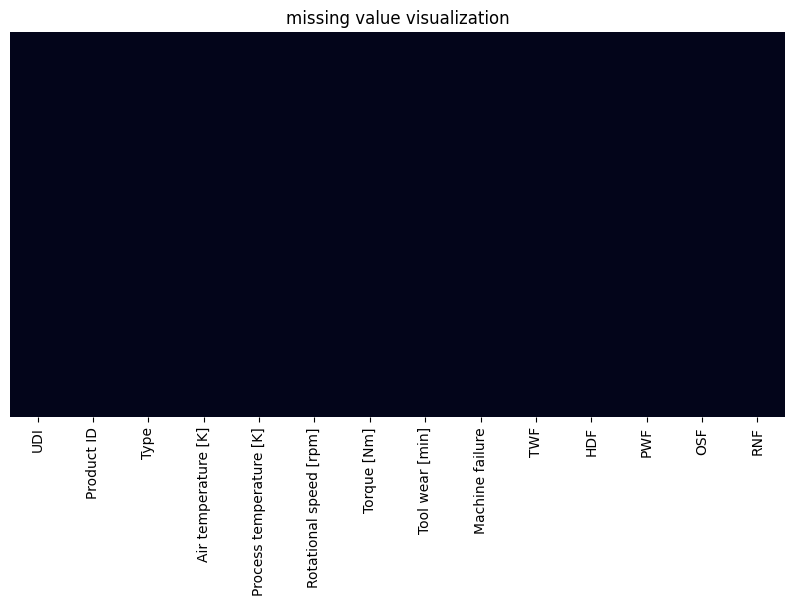

In [12]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(),cbar=False,yticklabels=False
           )
plt.title("missing value visualization")
plt.show()

In [13]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [15]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [16]:
X = df[[
    "Type","Air temperature [K]",
       "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]",
       "Tool wear [min]"
]]
y = df['Machine failure']

In [17]:
print("input shape",X.shape)
print("output shape",y.shape)

input shape (10000, 6)
output shape (10000,)


In [18]:
categorical_featues = ['Type']
numerical_featues = ['Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']

In [19]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),numerical_featues),
        ('cat',OneHotEncoder(handle_unknown='ignore'),categorical_featues)
    ]
)

In [21]:
linear_svm = Pipeline(
    steps = [
    ('preprocessor',preprocessor),
    ('linear_svm',SVC(kernel='linear'))
])
# train model
linear_svm.fit(X_train,y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('linear_svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [22]:
y_pred = linear_svm.predict(X_test)

In [23]:
accuracy_linear = accuracy_score(y_pred,y_test)
precision_linear = precision_score(y_pred,y_test,zero_division=0)
recall_score_linear = recall_score(y_pred,y_test,zero_division=0)
f1_score_linear = f1_score(y_pred,y_test,zero_division=0)
print("accuracy",accuracy_linear)
print("precision",precision_linear)
print("recall",recall_score_linear)
print("f1_score",f1_score_linear)

accuracy 0.966
precision 0.0
recall 0.0
f1_score 0.0


In [24]:
print(classification_report(y_pred,y_test,target_names=["no Failure","Failure"],zero_division = 0))

              precision    recall  f1-score   support

  no Failure       1.00      0.97      0.98      2000
     Failure       0.00      0.00      0.00         0

    accuracy                           0.97      2000
   macro avg       0.50      0.48      0.49      2000
weighted avg       1.00      0.97      0.98      2000



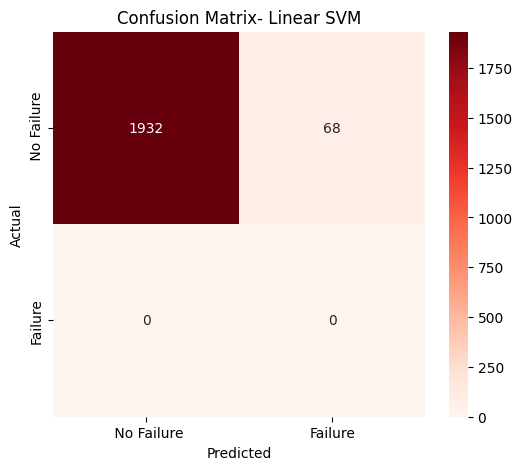

In [25]:
cm_linear = confusion_matrix(y_pred,y_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Reds",
            xticklabels = [" No Failure" , "Failure"],
            yticklabels =[" No Failure" , "Failure"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix- Linear SVM")
plt.show()

In [26]:
rbf_svm = Pipeline(
    steps = [
    ('preprocessor',preprocessor),
    ('rbf_svm',SVC(kernel='rbf'))
])
# train model
rbf_svm.fit(X_train,y_train)
print("RBF svm training completed")

RBF svm training completed


In [27]:
y_pred_rbf = rbf_svm.predict(X_test)

In [28]:
accuracy_rbf = accuracy_score(y_pred_rbf,y_test)
precision_rbf = precision_score(y_pred_rbf,y_test,zero_division=0)
recall_score_rbf = recall_score(y_pred_rbf,y_test,zero_division=0)
f1_score_rbf = f1_score(y_pred_rbf,y_test,zero_division=0)
print("RBF SVM results")
print("accuracy",accuracy_rbf)
print("precision",precision_rbf)
print("recall",recall_score_rbf)
print("f1_score",f1_score_rbf)


RBF SVM results
accuracy 0.972
precision 0.20588235294117646
recall 0.875
f1_score 0.3333333333333333


In [29]:
print(classification_report(y_pred_rbf,y_test,target_names=["no Failure","Failure"],zero_division = 0))

              precision    recall  f1-score   support

  no Failure       1.00      0.97      0.99      1984
     Failure       0.21      0.88      0.33        16

    accuracy                           0.97      2000
   macro avg       0.60      0.92      0.66      2000
weighted avg       0.99      0.97      0.98      2000



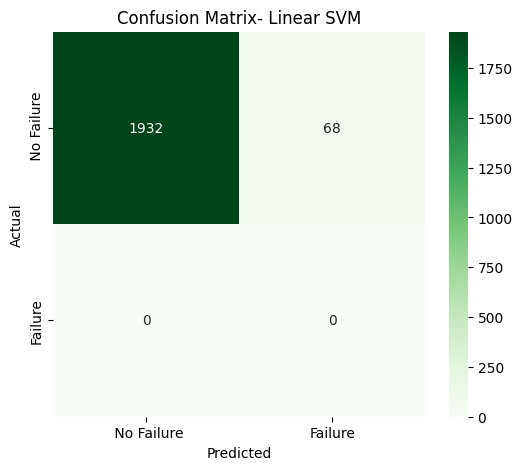

In [30]:
cm_rbf = confusion_matrix(y_pred_rbf,y_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Greens",
            xticklabels = [" No Failure" , "Failure"],
            yticklabels =[" No Failure" , "Failure"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix- Linear SVM")
plt.show()

In [31]:
comparison = pd.DataFrame({
    "Linear SVM":[accuracy_linear,precision_linear,recall_score_linear,f1_score_linear],
    "RBF SVM":[accuracy_rbf,precision_rbf,recall_score_rbf,f1_score_rbf]})
comparison

,Linear SVM,RBF SVM
0,0.966,0.972000
1,0.000,0.205882
2,0.000,0.875000
3,0.000,0.333333


In [32]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps = [
    ('preprocessor',preprocessor),
    ('classifier',SVC())
])


In [33]:
param_grid = [{"classifier__kernel": ["linear"],"classifier__C": [1,10]},
              {"classifier__kernel": ["rbf"],"classifier__C": [0.1,1,10],"classifier__gamma": ["scale",0.01,0.1,1]}]

In [34]:
grid_search = GridSearchCV(estimator=pipeline,param_grid=param_grid,cv=5,verbose=1,n_jobs=-1,scoring="f1")

In [35]:
grid_search.fit(X_train,y_train)
print("GRID searchCV completed.")
print("Best parameters found:", grid_search.best_params_)
print("Best F1-score:", grid_search.best_score_)

Fitting 5 folds for each of 14 candidates, totalling 70 fits
GRID searchCV completed.
Best parameters found: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best F1-score: 0.6538878032893665


In [36]:
print("best parameters:")
print(grid_search.best_params_)

best parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
